<a href="https://colab.research.google.com/github/lizlorenzana931109-art/FinPredict-Actividad5/blob/main/fuentes/entrena_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FinPredict | Actividad 5

## Gestión de datos, entrenamiento y ajuste de modelos

**Objetivo:** Desarrollar un modelo de clasificación para predecir el incumplimiento hipotecario utilizando datos sintéticos.

**Alcance:** 50,000 contratos hipotecarios con aperturas escalonadas entre 2021 y 2025.

**Metodología:** Preparación y validación de datos, análisis exploratorio, entrenamiento de Regresión Logística y Random Forest, validación cruzada y registro de experimentos con MLflow.

**Herramientas:** Python, Google Colab, GitHub, scikit-learn y MLflow.

In [1]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 01. Preparación del entorno
# ============================================================

# Instalación de librerías necesarias
%pip -q install mlflow pyarrow

# Librerías para manipulación y análisis de datos
import pandas as pd
import numpy as np
import matplotlib
import sklearn
import pyarrow
import mlflow

# Información del entorno
print("FINPREDICT | Validación del entorno")
print("-" * 45)

print(f"Pandas:        {pd.__version__}")
print(f"NumPy:         {np.__version__}")
print(f"Matplotlib:    {matplotlib.__version__}")
print(f"Scikit-learn:  {sklearn.__version__}")
print(f"PyArrow:       {pyarrow.__version__}")
print(f"MLflow:        {mlflow.__version__}")

print("-" * 45)
print("Entorno preparado correctamente.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 02. Configuración y generación de datos sintéticos

### Objetivo

Construir un conjunto de datos sintéticos de 50,000 contratos hipotecarios, con aperturas escalonadas entre enero de 2021 y diciembre de 2025.

La simulación permitirá generar información contractual, sociodemográfica y transaccional para estudiar patrones de comportamiento de pago e identificar señales asociadas al incumplimiento hipotecario.

### Criterios metodológicos

- **Reproducibilidad:** utilización de una semilla aleatoria fija.
- **Consistencia temporal:** los movimientos deberán respetar la fecha de apertura de cada contrato.
- **Consistencia financiera:** los importes y condiciones contractuales deberán seguir reglas de negocio documentadas.
- **Calidad de datos:** se incorporarán inconsistencias controladas para evaluar los procesos de limpieza.
- **Uso responsable:** los datos serán completamente sintéticos y las variables sociodemográficas estarán sujetas a evaluación ética.

Los resultados representarán un escenario simulado y no deberán interpretarse como evidencia del comportamiento real de una cartera hipotecaria.

In [2]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 02. Parámetros generales del dataset
# ============================================================

from datetime import datetime

# Semilla para reproducibilidad
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# Universo de contratos
NUM_CONTRATOS = 50_000

# Periodo de simulación
FECHA_INICIO = pd.Timestamp("2021-01-01")
FECHA_FIN = pd.Timestamp("2025-12-31")

# Parámetros generales
MONEDA = "MXN"
TIPO_PROBLEMA = "Clasificación binaria"

# Información del proyecto
print("FINPREDICT | Configuración del dataset")
print("-" * 50)
print(f"Contratos:       {NUM_CONTRATOS:,}")
print(f"Periodo:         {FECHA_INICIO.date()} a {FECHA_FIN.date()}")
print(f"Semilla:         {SEMILLA}")
print(f"Moneda:          {MONEDA}")
print(f"Problema:        {TIPO_PROBLEMA}")
print("-" * 50)
print("Configuración inicializada correctamente.")


FINPREDICT | Configuración del dataset
--------------------------------------------------
Contratos:       50,000
Periodo:         2021-01-01 a 2025-12-31
Semilla:         42
Moneda:          MXN
Problema:        Clasificación binaria
--------------------------------------------------
Configuración inicializada correctamente.


In [3]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 03. Generación de identificadores y fechas de apertura
# ============================================================

# Identificadores únicos de los 50,000 contratos
ids_credito = [
    f"HIP{i:06d}"
    for i in range(1, NUM_CONTRATOS + 1)
]

# Fechas aleatorias dentro del periodo definido
dias_periodo = (FECHA_FIN - FECHA_INICIO).days + 1

dias_aleatorios = rng.integers(
    low=0,
    high=dias_periodo,
    size=NUM_CONTRATOS
)

fechas_apertura = (
    FECHA_INICIO + pd.to_timedelta(dias_aleatorios, unit="D")
)

# Tabla inicial de contratos
df_contratos = pd.DataFrame({
    "id_credito": ids_credito,
    "fecha_apertura": fechas_apertura
})

# Ordenar por identificador
df_contratos = df_contratos.sort_values(
    "id_credito"
).reset_index(drop=True)

# Validaciones iniciales
assert len(df_contratos) == NUM_CONTRATOS
assert df_contratos["id_credito"].is_unique
assert df_contratos["fecha_apertura"].between(
    FECHA_INICIO, FECHA_FIN
).all()

print("FINPREDICT | Contratos generados")
print("-" * 45)
print(f"Total de contratos: {len(df_contratos):,}")
print(f"IDs únicos:         {df_contratos['id_credito'].nunique():,}")
print(f"Fecha mínima:       {df_contratos['fecha_apertura'].min().date()}")
print(f"Fecha máxima:       {df_contratos['fecha_apertura'].max().date()}")
print("-" * 45)

display(df_contratos.head(10))


FINPREDICT | Contratos generados
---------------------------------------------
Total de contratos: 50,000
IDs únicos:         50,000
Fecha mínima:       2021-01-01
Fecha máxima:       2025-12-31
---------------------------------------------


,id_credito,fecha_apertura
0,HIP000001,2021-06-12
1,HIP000002,2024-11-14
2,HIP000003,2024-04-10
3,HIP000004,2023-03-13
4,HIP000005,2023-03-02
5,HIP000006,2025-04-17
6,HIP000007,2021-06-06
7,HIP000008,2024-06-27
8,HIP000009,2022-01-03
9,HIP000010,2021-06-21


In [5]:
# Librería para visualización de datos
import matplotlib.pyplot as plt

FINPREDICT | Distribución de aperturas


,contratos,porcentaje
fecha_apertura,,
2021,10016,20.03
2022,9959,19.92
2023,9975,19.95
2024,10144,20.29
2025,9906,19.81


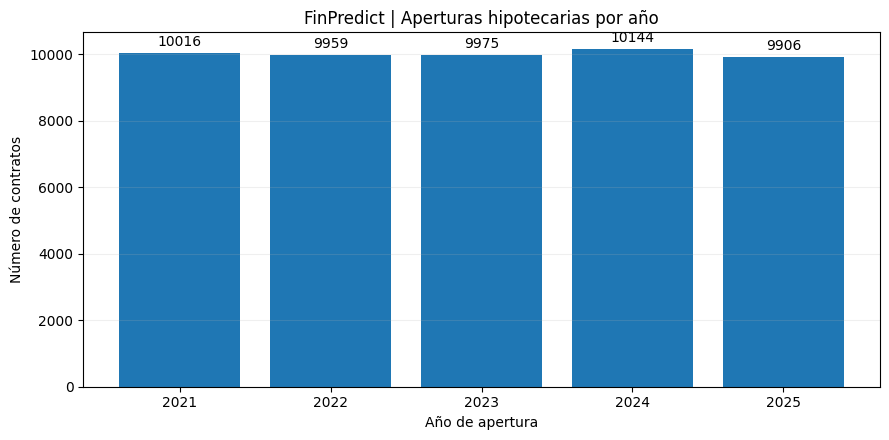

Validación: el universo de contratos está completo.


In [6]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 04. Análisis de aperturas por año
# ============================================================

# Distribución anual
distribucion_anual = (
    df_contratos["fecha_apertura"]
    .dt.year
    .value_counts()
    .sort_index()
)

# Porcentaje por año
resumen_aperturas = pd.DataFrame({
    "contratos": distribucion_anual,
    "porcentaje": (
        distribucion_anual / NUM_CONTRATOS * 100
    ).round(2)
})

print("FINPREDICT | Distribución de aperturas")
display(resumen_aperturas)

# Visualización
fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.bar(
    resumen_aperturas.index.astype(str),
    resumen_aperturas["contratos"]
)

ax.bar_label(barras, padding=3, fmt="%.0f")

ax.set_title("FinPredict | Aperturas hipotecarias por año")
ax.set_xlabel("Año de apertura")
ax.set_ylabel("Número de contratos")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# Validación del universo
assert distribucion_anual.sum() == NUM_CONTRATOS

print("Validación: el universo de contratos está completo.")


### Análisis de distribución temporal

Se generaron 50,000 contratos hipotecarios sintéticos, con fechas de apertura comprendidas entre el 1 de enero de 2021 y el 31 de diciembre de 2025.

El análisis exploratorio identificó una distribución aproximadamente uniforme entre los cinco años, con porcentajes anuales de 19.81% a 20.29%.

El año 2024 presentó la mayor concentración de aperturas (10,144 contratos), mientras que 2025 registró la menor (9,906 contratos).

No se identificaron desequilibrios temporales relevantes en la distribución anual. Este comportamiento es consistente con el mecanismo de generación aleatoria utilizado y no representa una tendencia observada en datos hipotecarios reales.

**Conclusión:** Se valida la distribución inicial de aperturas para continuar con la generación de características contractuales y financieras.


### 05. Metodología de generación y validación de condiciones financieras

**Objetivo:** Generar condiciones financieras consistentes para los 50,000 contratos hipotecarios sintéticos, utilizando supuestos controlados y una fórmula de amortización de pagos constantes.

#### Variables y supuestos de generación

| Variable | Metodología | Valores permitidos |
|---|---|---|
| `monto_original` | Distribución uniforme aleatoria | $300,000 a $5,000,000 MXN |
| `plazo_meses` | Distribución categórica ponderada | 120 (10%), 180 (20%), 240 (50%) y 360 (20%) |
| `tasa_interes_anual` | Distribución uniforme aleatoria | 7% a 15% anual |
| `pago_mensual` | Cálculo financiero | Amortización con mensualidades constantes |

Los rangos y probabilidades son **supuestos de simulación académica** y no representan estadísticas observadas de una cartera hipotecaria real.

#### Cálculo de la mensualidad

Se utiliza la fórmula de amortización francesa, bajo el supuesto de tasa fija y pagos mensuales constantes:

$$
M = P \frac{r(1+r)^n}{(1+r)^n-1}
$$

Donde:

- **M:** mensualidad contractual en pesos mexicanos.
- **P:** monto original financiado.
- **r:** tasa de interés mensual, calculada como tasa anual porcentual dividida entre 100 y entre 12.
- **n:** número total de mensualidades del crédito.

$$
r = \frac{\text{tasa de interés anual}}{100 \times 12}
$$

La mensualidad considera capital e intereses. No incluye seguros, comisiones, gastos adicionales ni ajustes por incumplimiento. Los cálculos se redondean a dos decimales para representar importes monetarios.

#### Resultados obtenidos

| Indicador | Resultado |
|---|---:|
| Contratos generados | 50,000 |
| Monto mínimo financiado | $300,062.43 MXN |
| Monto máximo financiado | $4,999,970.55 MXN |
| Mensualidad promedio | $28,603.07 MXN |

#### Validaciones de calidad

Se ejecutaron controles automatizados para comprobar que:

1. Los importes originales se encuentran dentro del rango definido.
2. Los plazos pertenecen exclusivamente al catálogo autorizado.
3. Las tasas anuales se encuentran entre 7% y 15%.
4. Todas las mensualidades calculadas son positivas.
5. No existen valores nulos en las cuatro variables financieras generadas.

**Resultado:** Todas las validaciones se ejecutaron satisfactoriamente.

#### Interpretación técnica

La generación incorpora variabilidad en monto, plazo y tasa de interés, manteniendo consistencia matemática entre las condiciones contractuales y la mensualidad calculada.

El pago mensual promedio de $28,603.07 MXN es un resultado del conjunto de supuestos sintéticos y no representa una estimación del mercado hipotecario mexicano.

Estas variables permitirán construir posteriormente las obligaciones de pago y contrastarlas con los movimientos realizados por cada crédito, para calcular indicadores de comportamiento y morosidad.

**Consideración metodológica:** La consistencia financiera demostrada corresponde al cálculo inicial de mensualidades. La validación integral de saldos, pagos, atrasos y ajustes se realizará cuando se construya el histórico transaccional.
  

In [7]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 05. Generación de condiciones financieras
# ============================================================

# 1. Monto original del crédito (MXN)
df_contratos["monto_original"] = np.round(
    rng.uniform(300_000, 5_000_000, NUM_CONTRATOS),
    2
)

# 2. Plazo del financiamiento
plazos = [120, 180, 240, 360]
probabilidades = [0.10, 0.20, 0.50, 0.20]

df_contratos["plazo_meses"] = rng.choice(
    plazos,
    size=NUM_CONTRATOS,
    p=probabilidades
)

# 3. Tasa anual fija, expresada en porcentaje
df_contratos["tasa_interes_anual"] = np.round(
    rng.uniform(7.0, 15.0, NUM_CONTRATOS),
    4
)

# 4. Cálculo de mensualidad contractual
P = df_contratos["monto_original"]
r = df_contratos["tasa_interes_anual"] / 100 / 12
n = df_contratos["plazo_meses"]

df_contratos["pago_mensual"] = np.round(
    P * (r * (1 + r)**n) / ((1 + r)**n - 1),
    2
)

# 5. Validaciones financieras
assert df_contratos["monto_original"].between(
    300_000, 5_000_000
).all()

assert df_contratos["plazo_meses"].isin(
    plazos
).all()

assert df_contratos["tasa_interes_anual"].between(
    7.0, 15.0
).all()

assert (df_contratos["pago_mensual"] > 0).all()

assert df_contratos[
    ["monto_original", "plazo_meses",
     "tasa_interes_anual", "pago_mensual"]
].notna().all().all()

print("FINPREDICT | Condiciones financieras generadas")
print("-" * 55)
print(f"Contratos: {len(df_contratos):,}")
print(f"Monto mínimo: ${df_contratos['monto_original'].min():,.2f}")
print(f"Monto máximo: ${df_contratos['monto_original'].max():,.2f}")
print(f"Pago mensual promedio: ${df_contratos['pago_mensual'].mean():,.2f}")
print("-" * 55)
print("Validaciones financieras satisfactorias.")

display(df_contratos.head(10))


FINPREDICT | Condiciones financieras generadas
-------------------------------------------------------
Contratos: 50,000
Monto mínimo: $300,062.43
Monto máximo: $4,999,970.55
Pago mensual promedio: $28,603.07
-------------------------------------------------------
Validaciones financieras satisfactorias.


,id_credito,fecha_apertura,monto_original,plazo_meses,tasa_interes_anual,pago_mensual
0,HIP000001,2021-06-12,4784933.89,360,10.3400,43198.32
1,HIP000002,2024-11-14,4955117.17,180,11.6005,58202.15
2,HIP000003,2024-04-10,4215882.23,360,10.8975,39822.65
3,HIP000004,2023-03-13,2386254.37,360,11.6595,23921.70
4,HIP000005,2023-03-02,2872824.08,360,13.8317,33656.96
5,HIP000006,2025-04-17,2665542.79,180,12.1300,32214.27
6,HIP000007,2021-06-06,1031633.61,240,8.5900,9011.61
7,HIP000008,2024-06-27,4315746.60,240,9.6991,40791.19
8,HIP000009,2022-01-03,3476217.40,240,11.4310,36906.28
9,HIP000010,2021-06-21,3298297.40,180,11.6403,38825.06


## 06. Análisis exploratorio de condiciones financieras

### Objetivo

Evaluar la distribución estadística de los montos originales, las mensualidades, las tasas de interés y los plazos de los 50,000 contratos hipotecarios sintéticos.

El análisis permitirá identificar patrones de concentración, dispersión y posibles valores atípicos, diferenciando entre variaciones financieras válidas y errores de calidad de datos.

**Metodología:** se utilizarán estadísticas descriptivas, histogramas y diagramas de caja (*boxplots*).

Los valores atípicos identificados no serán eliminados automáticamente, ya que podrían corresponder a condiciones contractuales válidas dentro de los rangos definidos para la simulación.

FINPREDICT | Estadísticas financieras
-------------------------------------------------------


,monto_original,plazo_meses,tasa_interes_anual,pago_mensual
count,50000.00,50000.00,50000.00,50000.00
mean,2656556.67,240.05,11.00,28603.07
std,1354038.53,71.05,2.31,15692.15
min,300062.43,120.00,7.00,2087.83
25%,1483200.36,180.00,8.99,15383.03
50%,2663115.60,240.00,10.99,27827.34
75%,3823750.31,240.00,13.01,40161.19
max,4999970.55,360.00,15.00,79864.65


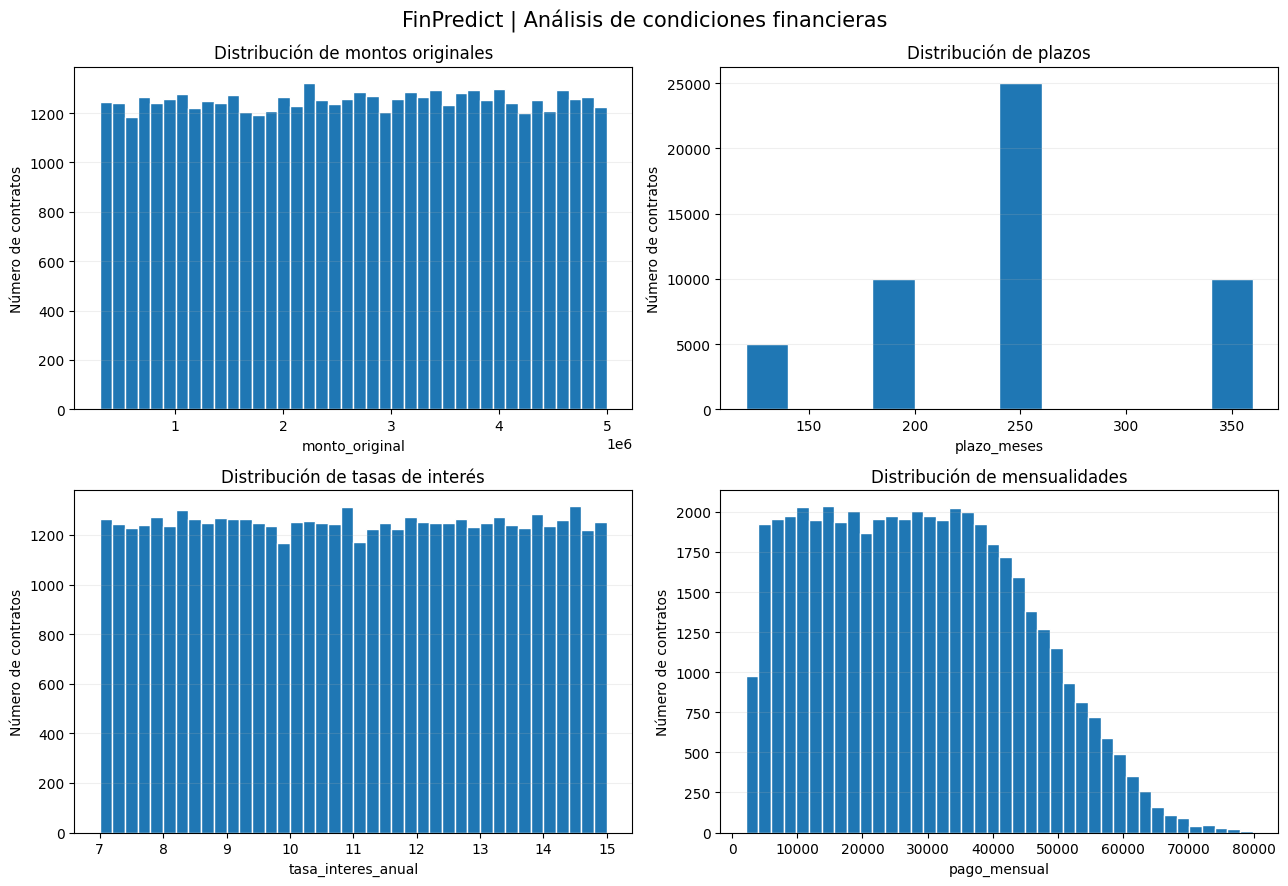


FINPREDICT | Valores atípicos potenciales
-------------------------------------------------------
monto_original: 0 (0.00%)
pago_mensual: 12 (0.02%)


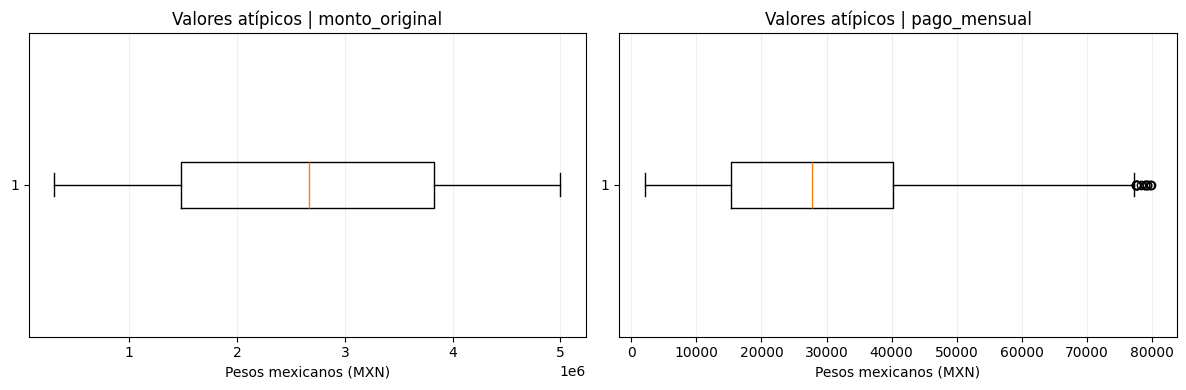

In [8]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 06. Análisis exploratorio de condiciones financieras
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Variables financieras para el análisis
variables_financieras = [
    "monto_original",
    "plazo_meses",
    "tasa_interes_anual",
    "pago_mensual"
]

# Estadísticas descriptivas
print("FINPREDICT | Estadísticas financieras")
print("-" * 55)

display(
    df_contratos[variables_financieras]
    .describe()
    .round(2)
)

# Histogramas
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

titulos = [
    "Distribución de montos originales",
    "Distribución de plazos",
    "Distribución de tasas de interés",
    "Distribución de mensualidades"
]

for ax, columna, titulo in zip(
    axes.flatten(),
    variables_financieras,
    titulos
):
    ax.hist(
        df_contratos[columna],
        bins=40 if columna != "plazo_meses" else 12,
        edgecolor="white"
    )

    ax.set_title(titulo)
    ax.set_xlabel(columna)
    ax.set_ylabel("Número de contratos")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "FinPredict | Análisis de condiciones financieras",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Detección estadística de valores atípicos (IQR)
print("\nFINPREDICT | Valores atípicos potenciales")
print("-" * 55)

for columna in ["monto_original", "pago_mensual"]:
    q1 = df_contratos[columna].quantile(0.25)
    q3 = df_contratos[columna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = df_contratos[
        (df_contratos[columna] < limite_inferior) |
        (df_contratos[columna] > limite_superior)
    ]

    print(
        f"{columna}: {len(atipicos):,} "
        f"({len(atipicos) / NUM_CONTRATOS * 100:.2f}%)"
    )

# Diagramas de caja
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, columna in zip(
    axes,
    ["monto_original", "pago_mensual"]
):
    ax.boxplot(
        df_contratos[columna].dropna(),
        vert=False
    )

    ax.set_title(f"Valores atípicos | {columna}")
    ax.set_xlabel("Pesos mexicanos (MXN)")
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()



### 06.1. Resultados del análisis exploratorio financiero

Se analizaron las condiciones financieras de 50,000 contratos hipotecarios sintéticos mediante estadísticas descriptivas, histogramas y detección de valores atípicos utilizando el rango intercuartílico (IQR).

#### Principales resultados

| Indicador | Resultado |
|---|---:|
| Monto original promedio | $2,656,556.67 MXN |
| Plazo promedio | 240.05 meses |
| Tasa de interés promedio | 11.00% anual |
| Mensualidad promedio | $28,603.07 MXN |
| Mensualidad mínima | $2,087.83 MXN |
| Mensualidad máxima | $79,864.65 MXN |
| Valores atípicos en monto original | 0 |
| Valores atípicos en mensualidad | 12 (0.024%) |

#### Interpretación

Los montos originales y las tasas presentan estadísticas centrales consistentes con los rangos de generación definidos.

El plazo promedio es cercano a 240 meses, correspondiente a 20 años, en concordancia con la distribución de probabilidades establecida.

Se identificaron 12 mensualidades potencialmente atípicas mediante el método IQR. Estos registros representan el 0.024% de la población.

La presencia de mensualidades elevadas no constituye por sí misma un error de calidad, ya que puede explicarse por combinaciones válidas de importe financiado, tasa de interés y plazo contractual.

#### Decisión de tratamiento

Los 12 registros permanecerán sujetos a validación financiera individual. No se eliminarán automáticamente por su clasificación estadística.

Esta decisión evita descartar observaciones válidas y preserva la variabilidad de las condiciones contractuales simuladas.

#### Conclusión

El análisis inicial no evidencia inconsistencias en los rangos financieros configurados. La evaluación de valores atípicos permite distinguir entre variabilidad estadística y posibles errores, fortaleciendo los criterios de calidad de datos del proyecto FinPredict.


In [9]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 07. Auditoría de mensualidades atípicas
# ============================================================

q1 = df_contratos["pago_mensual"].quantile(0.25)
q3 = df_contratos["pago_mensual"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

df_atipicos = df_contratos.loc[
    (df_contratos["pago_mensual"] < limite_inferior) |
    (df_contratos["pago_mensual"] > limite_superior)
].copy()

# Recalcular independientemente la mensualidad esperada
p = df_atipicos["monto_original"]
r = df_atipicos["tasa_interes_anual"] / 100 / 12
n = df_atipicos["plazo_meses"]

df_atipicos["mensualidad_recalculada"] = np.round(
    p * (r * (1 + r)**n) / ((1 + r)**n - 1),
    2
)

df_atipicos["diferencia_calculo"] = (
    df_atipicos["pago_mensual"] -
    df_atipicos["mensualidad_recalculada"]
).round(2)

print("FINPREDICT | Auditoría financiera de atípicos")
print(f"Límite inferior IQR: ${limite_inferior:,.2f}")
print(f"Límite superior IQR: ${limite_superior:,.2f}")
print(f"Registros detectados: {len(df_atipicos):,}")

display(
    df_atipicos[[
        "id_credito",
        "monto_original",
        "plazo_meses",
        "tasa_interes_anual",
        "pago_mensual",
        "mensualidad_recalculada",
        "diferencia_calculo"
    ]]
)

# Validación del cálculo
assert np.isclose(
    df_atipicos["diferencia_calculo"], 0, atol=0.01
).all()

print("Validación: las mensualidades atípicas coinciden con la fórmula.")


FINPREDICT | Auditoría financiera de atípicos
Límite inferior IQR: $-21,784.21
Límite superior IQR: $77,328.44
Registros detectados: 12


,id_credito,monto_original,plazo_meses,tasa_interes_anual,pago_mensual,mensualidad_recalculada,diferencia_calculo
18834,HIP018835,4862326.09,120,14.7003,77556.32,77556.32,0.0
28232,HIP028233,4859723.35,120,14.6915,77488.76,77488.76,0.0
28852,HIP028853,4976789.52,120,14.6471,79220.88,79220.88,0.0
30499,HIP030500,4982281.60,120,14.7886,79737.84,79737.84,0.0
32360,HIP032361,4896867.45,120,14.5647,77703.33,77703.33,0.0
36247,HIP036248,4897244.34,120,14.7351,78217.12,78217.12,0.0
38270,HIP038271,4946883.46,120,14.8094,79234.10,79234.10,0.0
41400,HIP041401,4952493.68,120,14.9880,79864.65,79864.65,0.0
45011,HIP045012,4910099.85,120,14.9188,78973.09,78973.09,0.0
45797,HIP045798,4838022.47,120,14.8274,77543.64,77543.64,0.0


Validación: las mensualidades atípicas coinciden con la fórmula.



### 06.2. Auditoría y tratamiento de valores atípicos

Se realizó una revisión individual de los 12 contratos cuya mensualidad superó los límites establecidos mediante el método del rango intercuartílico (IQR).

**Resultados de la auditoría:**

- Límite inferior IQR: -$21,784.21 MXN.
- Límite superior IQR: $77,328.44 MXN.
- Registros identificados: 12 (0.024%).
- Diferencias entre mensualidad registrada y recalculada: $0.00 MXN en todos los casos.

Los contratos identificados presentan montos financiados elevados, plazos de 120 meses y tasas de interés cercanas al extremo superior del rango simulado.

Estas condiciones explican las mensualidades elevadas y son consistentes con la fórmula de amortización utilizada.

**Decisión de calidad de datos:** conservar los 12 registros sin modificaciones.

**Justificación:** los valores atípicos responden a combinaciones válidas de los parámetros financieros definidos. Eliminarlos implicaría perder variabilidad del conjunto de datos sin evidencia de un error.

**Conclusión:** la detección estadística debe complementarse con reglas de negocio antes de decidir la modificación o eliminación de observaciones.
